# Plot Cross Section Composites
This notebook plots composite files previously created by A. Aiyyer. Select the file then plot the cross section. Each file represents the filtered variable field at all levels for all cases at a particular base point. 
- A. Aiyyer
- A. Thornton

In [5]:
# IMPORTS
import numpy as np
import xarray as xr
from datetime import date, timedelta
import pandas as pd

from metpy.units import units
from metpy.calc import potential_temperature
import metpy.constants as constants

import matplotlib.pyplot as plt

from matplotlib.ticker import ScalarFormatter
import metpy.calc as mpcalc
import geocat.viz as gv

In [27]:
do_temp = False
do_dse = False
do_moist = True
basepts = [5, 3, 1]

# Selections:
level = [850,600]
stormTracks = ['N', 'N', 'O'],['S', 'S', 'O']
Ltitle = ['Northern Track', 'Northern Track', 'Northern Track'], ['Southern Track', 'Southern Track', 'Southern Track']
    
deltalon = 30
lagHour = 0

label = ['(a) ','(b) ','(c) '], ['(d) ','(e) ','(f) ']

plotsdir = 'plots/cross_sections/' # save figure in this location

## Cross Section Plots, Lag vs Height
Plots cross sections for either temp and winds (plot outcome #1), or vorticity/omega/specific humidity (plot outcome #2), at each base point location for a lag vs height

In [32]:
# FUNCTION TO RETRIEVE TEMP DATA 
def get_temp_data(basept, level):
    data_path = '/glade/u/home/athornton/temp/refV' + str(level) + '/'

    # get wind data
    fileName = data_path + 'XSec_v__Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc'
    ds_v = xr.open_dataset(fileName)
    
    # attach base points to dataset
    Reflat = ds_v.Reflat.values
    Reflon = ds_v.Reflon.values
    V = ds_v.V_prime.sel(longitude=Reflon)
    V.attrs['lonRef'] = Reflon
    V.attrs['latRef'] = Reflat
    
    # get temp data
    fileName = data_path + 'XSec_t__Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc'
    ds_t = xr.open_dataset(fileName)
    T = ds_t.T_prime.sel(longitude=Reflon)

    # get pv data 
    fileName_pv = data_path + f'XSec_pv__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_pv = xr.open_dataset(fileName_pv)
    PV = ds_pv.PV_prime.sel(longitude=Reflon)

     # get mse data 
    fileName_dse = data_path + f'XSec_dse__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_mse = xr.open_dataset(fileName_dse)
    DSE = ds_dse.DSE_prime.sel(longitude=Reflon).metpy.quantify()    

    return V, T, PV, DSE

In [33]:
# FUNCTION TO RETRIEVE MOISTURE DATA 
def get_data(basept, level):
    data_path = '/glade/u/home/athornton/temp/refV' + str(level) + '/'

    # get wind data
    fileName = data_path + 'XSec_w__Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc'
    ds_w = xr.open_dataset(fileName)
    
    # attach base points to dataset
    Reflat = ds_w.Reflat.values
    Reflon = ds_w.Reflon.values
    W = ds_w.W_prime.sel(longitude=Reflon)
    W.attrs['lonRef'] = Reflon
    W.attrs['latRef'] = Reflat
    
    # get moist data
    fileName = data_path + 'XSec_q__Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc'
    ds_q = xr.open_dataset(fileName)
    Q = ds_q.Q_prime.sel(longitude=Reflon)

    # get vort data
    fileName = data_path + 'XSec_vo__Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc'
    ds_vo = xr.open_dataset(fileName)
    VO = ds_vo.VO_prime.sel(longitude=Reflon)

     # get pv data 
    fileName_pv = data_path + f'XSec_pv__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_pv = xr.open_dataset(fileName_pv)
    PV = ds_pv.PV_prime.sel(longitude=Reflon)

     # get mse data 
    fileName_mse = data_path + f'XSec_mse__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_mse = xr.open_dataset(fileName_mse)
    MSE = ds_mse.MSE_prime.sel(longitude=Reflon).metpy.quantify()    
    

    return W, Q, PV, MSE

In [30]:
# PLOTTING FUNCTION
def plotting():
    if do_temp==True:
        # Some kwargs ...
        clevs1 = np.arange(-1.5,1.5,.2)    # contour levels for temperature
        clevs2 = np.arange(-5.5, 6.6, 1.) # contour levels for winds
        clevs3 = np.arange(-2.e-7, 2.e-7, 4.e-8)  # contour levels for pv

        cmap = 'coolwarm'                 # cmap for temperature
        norm = plt.Normalize(vmin=-2.e-7, vmax=2.e-7) #(vmin=-1.5, vmax=1.5) # for colorbar  
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm) # for colorbar
        #cbartitle = 'Temperature (K)'
        cbartitle = 'PV'
        title = 'PV, v-winds'
        file_save = '_lagvheight_PV_v.png'
        
        # Plot filled colors (temperature)
        vort = ax[i,j].contourf(PV.Lag, PV.level, PV.T, cmap=cmap, levels=clevs3, extend='both')

        #temp = ax[i,j].contourf(DSE.Lag, DSE.level, DSE.T, cmap=cmap, levels=clevs1, extend='both')
        # Note: have to transpose datasets because lag is positioned after level
        
        #Plot contour lines (v-winds)
        v_winds = ax[i,j].contour(V.Lag, V.level, V.T, colors='black', levels=clevs2, linewidths=1.)

    if do_dse==True:
        # Some kwargs ...
        clevs1 = np.arange(-1.5,1.5,.2)    # contour levels for temperature
        clevs2 = np.arange(-5.5, 6.6, 1.) # contour levels for winds
        clevs3 = np.arange(-2.e-7, 2.e-7, 4.e-8)  # contour levels for pv

        cmap = 'coolwarm'                 # cmap for temperature
        norm = plt.Normalize(vmin=-2.e-7, vmax=2.e-7) #(vmin=-1.5, vmax=1.5) # for colorbar  
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm) # for colorbar
        #cbartitle = 'Temperature (K)'
        cbartitle = 'DSE'
        title = 'DSE, v-winds'
        file_save = '_lagvheight_DSE_v.png'
        
        # Plot filled colors (temperature)
        temp = ax[i,j].contourf(DSE.Lag, DSE.level, DSE.T, cmap=cmap, levels=clevs1, extend='both')
        # Note: have to transpose datasets because lag is positioned after level
        
        #Plot contour lines (v-winds)
        v_winds = ax[i,j].contour(V.Lag, V.level, V.T, colors='black', levels=clevs2, linewidths=1.)

    if do_moist==True:
        # Some kwargs ...
        #clevs1 = np.arange(-0.002, 0.002, 0.0002)       # contour levels for specific humidity
        #clevs1 = np.arange(-3000, 3000, 300)       # contour levels for Lvq
        clevs1 = np.arange(-3, 3, 0.3)            # contour levels for MSE
        #clevs1 = np.arange(-1.5, 1.5, 0.2)        # contour levels for DSE
        clevs2 = np.arange(-0.04, 0.04, 0.03)     # contour levels for omega
        clevs3 = np.arange(-2.e-5, 2.e-5, 8.e-6)  # contour levels for vorticity
        clevs3 = np.arange(-2.e-7, 2.e-7, 8.e-8)  # contour levels for pv
        cmap = 'BrBG'                             # cmap for moisture
        norm = plt.Normalize(vmin=-3, vmax=3) # for colorbar  
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm) # for colorbar
        cbartitle = 'MSE ($kJ/kg$)'
        title =  'PV, MSE, Omega'
        file_save = '_lagvheight_w_MSE_pv.png'
        
        # Plot filled colors (moisture)
        moist = ax[i,j].contourf(MSE.Lag, MSE.level, MSE.T, cmap=cmap, levels=clevs1, extend='both') #linewidths=1.)
    
        # Plot contour lines (w-winds)
        w_winds = ax[i,j].contour(W.Lag, W.level, W.T, colors='red', levels=clevs2, linewidths=1.)
    
        # Plot contour lines (vorticity)
        vort = ax[i,j].contour(PV.Lag, PV.level, PV.T, colors='black', levels=clevs3, linewidths=1.) #extend='both')
    
    # Set y-axis to log scale
    #ax[i].set_yscale('log')
    
    gv.set_axes_limits_and_ticks(
        ax=ax[i, j],
        ylim=(1000, 100),  # Explicitly set the correct limits
        yticks=W["level"])
    
    # Force the y-axis to remain reversed
    #ax[i, j].set_ylim(1000, 100)  

    # Find at most 11 ticks on the y-axis at 'nice' locations
    max_yticks = 11
    yloc = plt.MaxNLocator(max_yticks)
    ax[i,j].yaxis.set_major_locator(yloc)

    # Change formatter or else tick values will be in exponential form
    ax[i,j].yaxis.set_major_formatter(ScalarFormatter())
            
    # Use geocat.viz.util convenience function to add major tick lines with no
    # minor ticks on left hand side y axis and some minor ticks on the x axis
    gv.add_major_minor_ticks(ax=ax[i,j],
                             x_minor_per_major=1,
                             y_minor_per_major=1,
                             labelsize=10)
    
    # Use geocat.viz.util convenience function to add titles and the pressure label
    gv.set_titles_and_labels(ax[i,j],
                             righttitle='Lat = ' + str(W.latRef) +', Lon = ' + str(W.lonRef), 
                             righttitlefontsize=15,
                             lefttitle= label[j][i]+ ' '+Ltitle[j][i],
                             lefttitlefontsize=15,
                             ylabel='Pressure (hPa)',
                             labelfontsize=15)
    return sm, cbartitle, title, file_save

/glade/derecho/scratch/athornton/tmp/ipykernel_120766/2773917291.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,0.85,1]) # the 2nd value allows space on the bottom for the colorbar


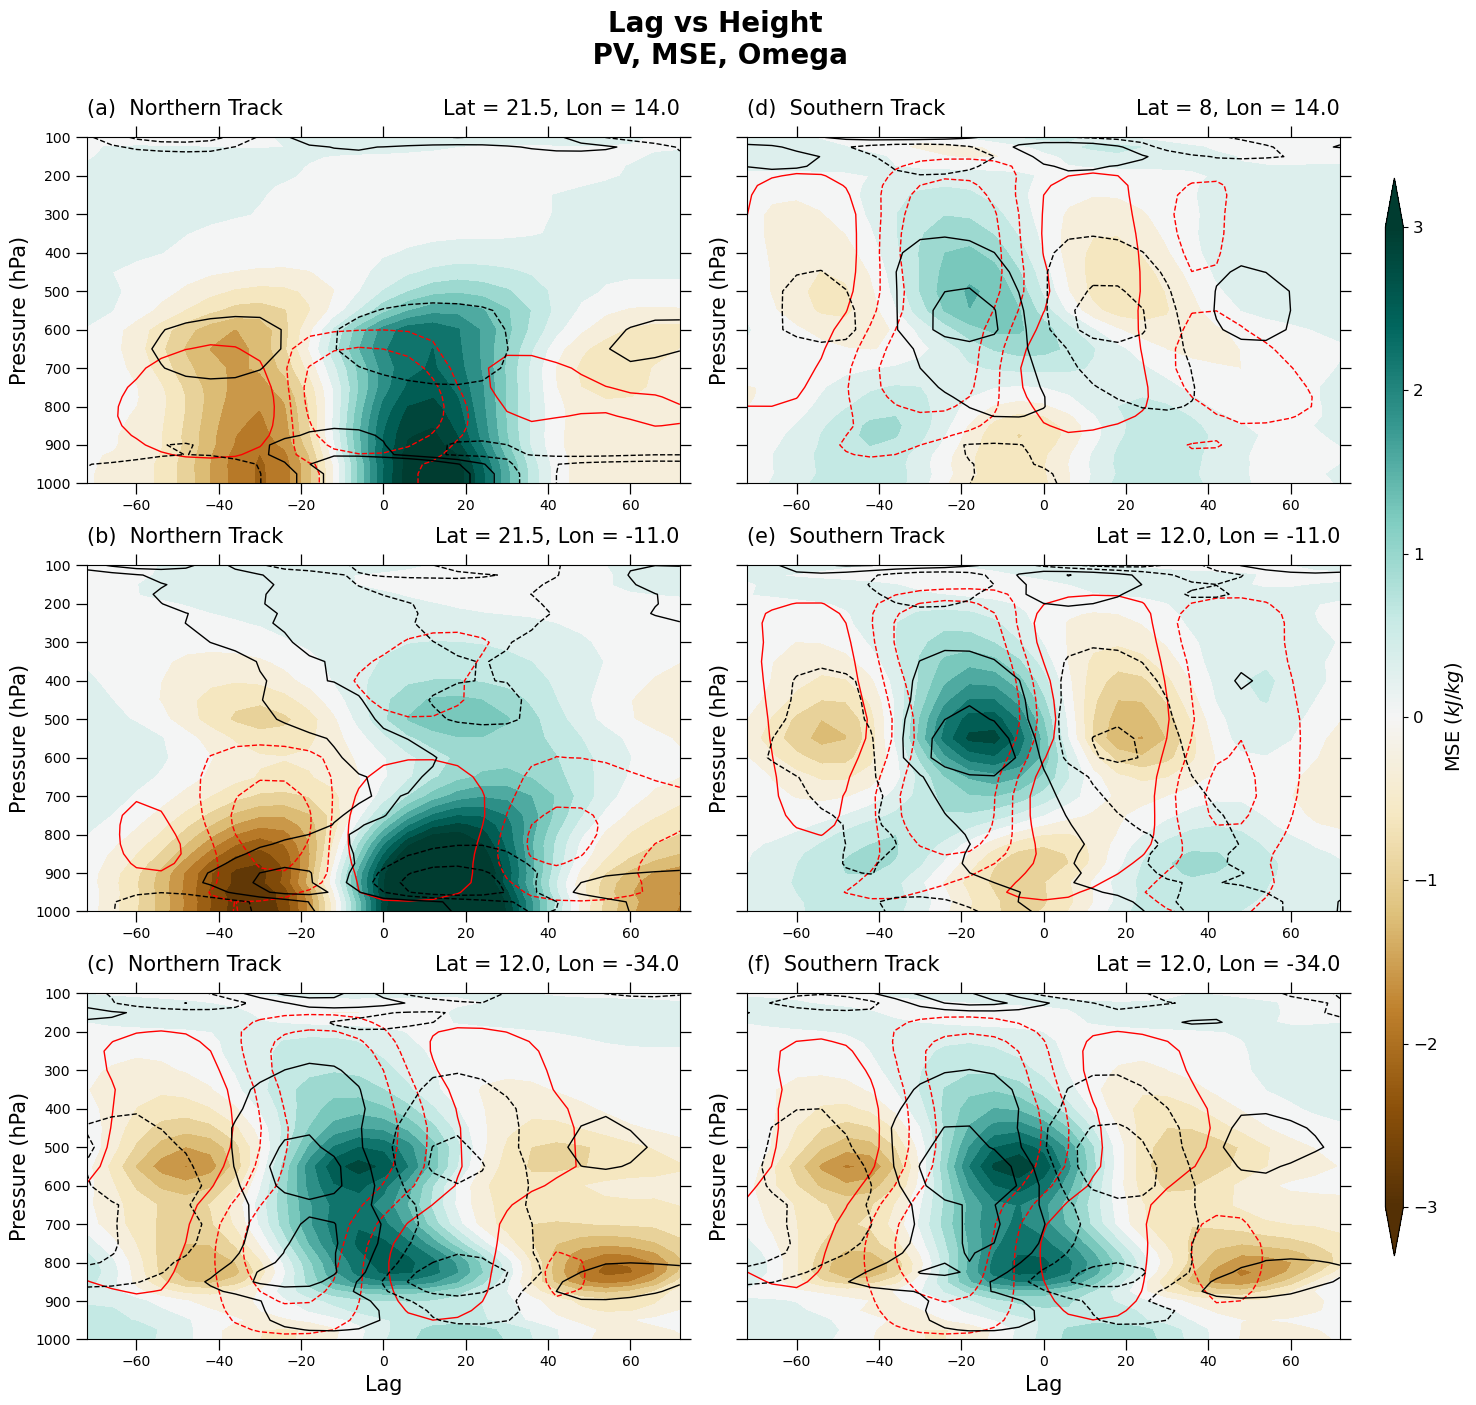

In [36]:
# Generate figure (set its size (width, height) in inches) and axes
fig, ax = plt.subplots(3,2, figsize=(16, 14), sharey=True)  # Share y-axis for consistency

plt.rcParams['savefig.dpi'] = 255 # Set image quality

#for basept, ax in zip(range(6, -1, -1), axes):  # Reverse basept order, regular axes order
#for i in range(0,3):
for j in range (0,2):
    for i in range(0, 3):    
        if do_dse==True:
            V, T, PV, DSE = get_temp_data(basepts[i], level[j])
        if do_moist==True:
            W, Q, PV, MSE = get_data(basepts[i], level[j])
        Lvq = Q*constants.water_heat_vaporization
        Lvq.metpy.convert_units('kJ/kg')
        DSE = MSE - Lvq
        sm, cbartitle, title, file_save = plotting()

# Create a dummy image to generate the color bar
sm.set_array([])
# Add the color bar
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.04, pad=0., extend='both', aspect=60)
cbar.set_label(cbartitle, fontsize=14)
cbar.ax.tick_params(labelsize=12) 

ax[2,0].set_xlabel('Lag', fontsize=15) # set lag label only on bottom panels
ax[2,1].set_xlabel('Lag', fontsize=15) # set lag label only on bottom panels

# main title
plt.suptitle('Lag vs Height\n '+title, weight='bold', fontsize=20, x=0.45,y=1.0) # main title
plt.tight_layout(rect=[0,0,0.85,1]) # the 2nd value allows space on the bottom for the colorbar
#plt.savefig(plotsdir+'Xsec_nolog_'+str(level)+file_save)
#plt.savefig('Xsec_winds_pv.png')

In [16]:
i = 0
j = 0
data = get_data(basepts[i], level[j])

## Cross Section Plots, Longitude vs Height
Plots cross sections for either temp and winds (plot outcome #1), or vorticity/omega/specific humidity (plot outcome #2), at each base point location for a longitude vs height.

In [123]:
# FUNCTION TO RETRIEVE MOISTURE, OMEGA, AND VORTICITY DATA
def get_data(basept, level, lagHour):
    data_path = '/glade/u/home/athornton/temp/refV' + str(level) + '/'

    # get omega data
    fileName_w = data_path + f'XSec_w__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_w = xr.open_dataset(fileName_w)

    # attach base points to dataset
    Reflat = ds_w.Reflat.values
    Reflon = ds_w.Reflon.values
    W = ds_w.W_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100, 1000))
    W.attrs['lonRef'] = Reflon
    W.attrs['latRef'] = Reflat

    # get moisture data
    fileName_q = data_path + f'XSec_q__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_q = xr.open_dataset(fileName_q)
    Q = ds_q.Q_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100, 1000))

    # get vorticity data
    fileName_vo = data_path + f'XSec_vo__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_vo = xr.open_dataset(fileName_vo)
    VO = ds_vo.VO_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100, 1000))

    # get pv data 
    fileName_pv = data_path + f'XSec_pv__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_pv = xr.open_dataset(fileName_pv)
    PV = ds_pv.PV_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100,1000))

    # get MSE data 
    fileName_mse = data_path + f'XSec_mse__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_mse = xr.open_dataset(fileName_mse)
    MSE = ds_mse.MSE_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100,1000))
        
    return W, MSE, PV

In [124]:
# FUNCTION TO RETRIEVE TEMP AND WIND DATA
def get_temp_data(basept, level, lagHour):
    data_path = '/glade/u/home/athornton/temp/refV' + str(level) + '/'

    # get wind data
    fileName_v = data_path + f'XSec_v__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_v = xr.open_dataset(fileName_v)

    # attach base points to dataset
    Reflat = ds_v.Reflat.values
    Reflon = ds_v.Reflon.values
    V = ds_v.V_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100, 1000))
    V.attrs['lonRef'] = Reflon
    V.attrs['latRef'] = Reflat

    # get temp data
    fileName_t = data_path + f'XSec_t__Lag_Composite_RefV_{level}hPa_track_point_{basept}.nc'
    ds_t = xr.open_dataset(fileName_t)
    T = ds_t.T_prime.sel(Lag=lagHour, longitude=slice(Reflon-deltalon, Reflon+deltalon), level=slice(100, 1000))

    return V, T

In [125]:
# PLOTTING FUNCTION
def plotting():
    
    # grabs settings for plot outcome #1
    if do_temp == True:
        # Some kwargs ...
        cmap = 'coolwarm'  # color map for temperature
        title = 'temperature and v-winds'
        cbartitle = 'Temperature (K)'
        clevs1 = np.arange(-1.,1.2,.2)    # contour levels for temperature
        clevs2 = np.arange(-5.5, 6.6, 1.) # contour levels for winds
        lonRef = V.lonRef
        norm = plt.Normalize(vmin=-1, vmax=1)  # for colorbar
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm) # for colorbar

        
        # Plot filled colors (temperature)
        temp = ax[i,j].contourf(T.longitude, T.level, T, cmap=cmap, levels=clevs1, extend='both')
    
        # Plot contour lines (v-winds)
        v_winds = ax[i,j].contour(V.longitude, V.level, V, colors='black', levels=clevs2, linewidths=1.)

        file_save = '_lag0_t_v.png'
    
    # grabs settings for plot outcome #2
    if do_moist == True:
        # Some kwargs ...
        cmap  = 'BrBG'  # color map for moisture
        title = 'PV, MSE, omega'
        cbartitle = 'MSE ($kg/kg$)'
        clevs1 = np.arange(-0.001, 0.001, 0.00015)      # contour levels for moisture
        clevs1 = np.arange(-2, 2, 0.2)           # contour levels for mse
        clevs2 = np.arange(-0.04, 0.04, 0.03)    # contour levels for omega
        clevs3 = np.arange(-2.e-5, 2.e-5, 8.e-6)      # contour levels for vorticity
        clevs3 = np.arange(-2.e-7, 2.e-7, 8.e-8) # clevs for PV
        lonRef = W.lonRef
        norm = plt.Normalize(vmin=-0.001, vmax=0.001)  # for colorbar
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm) # for colorbar

        # Plot filled colors (temperature)
        moist = ax[i,j].contourf(MSE.longitude, MSE.level, MSE, cmap=cmap, levels=clevs1, extend='both') #linewidths=1.)
    
        # Plot contour lines (v-winds)
        w_winds = ax[i,j].contour(W.longitude, W.level, W, colors='red', levels=clevs2, linewidths=1.)
    
        # Plot contour lines (v-winds)
        vort = ax[i,j].contour(PV.longitude, PV.level, PV, colors='black', levels=clevs3, linewidths=1.) #extend='both')
        
        file_save = '_lag0_w_mse_pv.png'


    
    # Plot base point
    ax[i,j].scatter(lonRef,level[j],s=80, facecolor='purple')

    gv.set_axes_limits_and_ticks(
        ax=ax[i, j],
        ylim=(1000, 100),  # Explicitly set the correct limits
        yticks=W["level"]
    )
    
    # Force the y-axis to remain reversed
    ax[i, j].set_ylim(1000, 100)  

    
    # Set y-axis to log scale
    #ax[i].set_yscale('log')
    
    
    # Find at most 11 ticks on the y-axis at 'nice' locations
    max_yticks = 11
    yloc = plt.MaxNLocator(max_yticks)
    ax[i,j].yaxis.set_major_locator(yloc)

    # Change formatter or else tick values will be in exponential form
    ax[i,j].yaxis.set_major_formatter(ScalarFormatter())
            
    # Use geocat.viz.util convenience function to add major tick lines with no
    # minor ticks on left hand side y axis and some minor ticks on the x axis
    gv.add_major_minor_ticks(ax=ax[i,j],
                             x_minor_per_major=1,
                             y_minor_per_major=1,
                             labelsize=10)
    
    # Use geocat.viz.util convenience function to add titles and the pressure label
    gv.set_titles_and_labels(ax[i,j],
                             righttitle='Lat = ' + str(W.latRef) +', Lon = ' + str(W.lonRef), 
                             righttitlefontsize=15,
                             lefttitle= label[j][i]+ ' '+Ltitle[j][i],
                             lefttitlefontsize=15)
    ax[i,0].set_ylabel('Pressure (hPa)', fontsize=15)

    return sm, cbartitle, title, file_save

/glade/derecho/scratch/athornton/tmp/ipykernel_37773/3180407487.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,0.85,1]) # the 3rd value allows space on the right for the colorbar


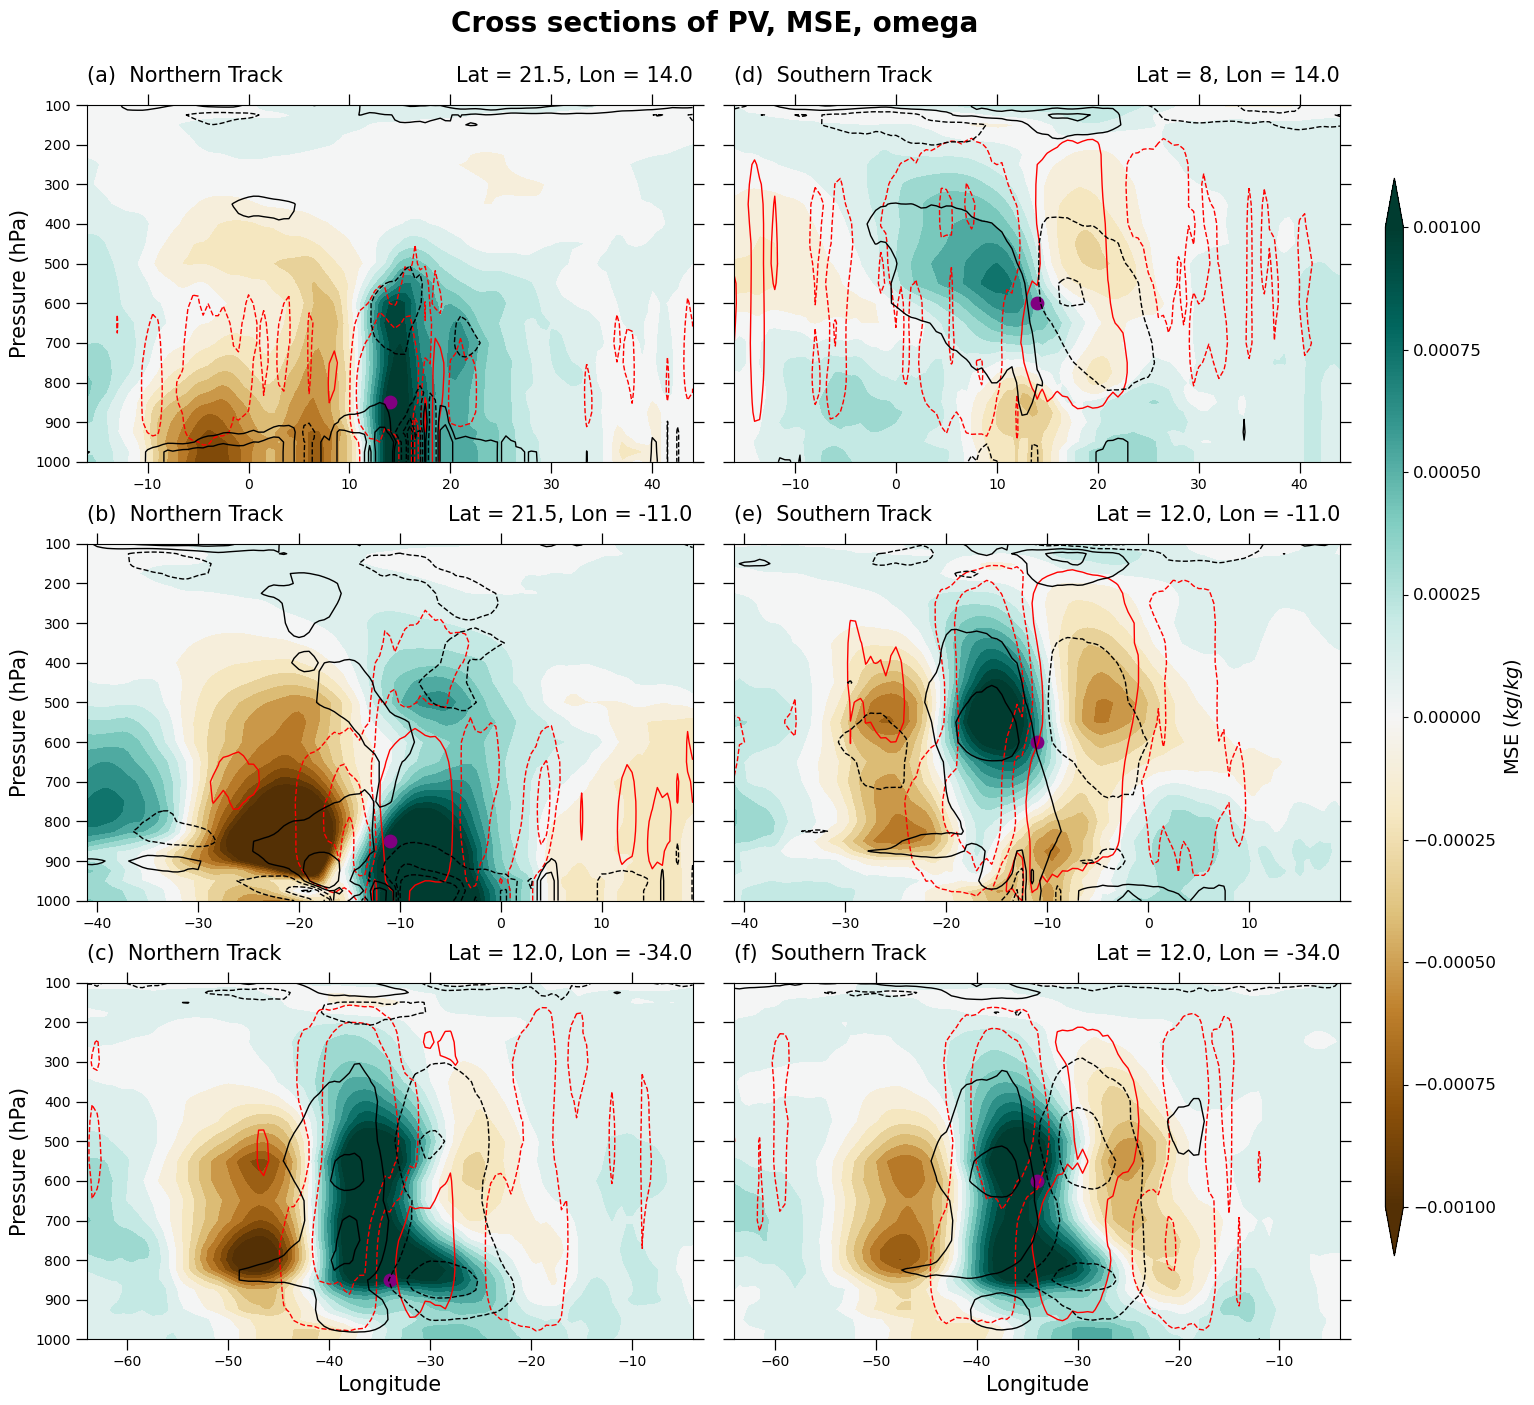

In [126]:
# Generate figure (set its size (width, height) in inches) and axes
fig, ax = plt.subplots(3,2, figsize=(16, 14), sharey=True)  # Share y-axis for consistency
plt.rcParams['savefig.dpi'] = 255 # Set image quality

#for basept, ax in zip(range(6, -1, -1), axes):  # Reverse basept order, regular axes order
#for i in range(0,3):
for j in range (0,2):
    for i in range(0, 3):
        #data_path = '/glade/derecho/scratch/aiyyer/data/composites/refV' + str(level[j]) + '/'
        V, T = get_temp_data(basepts[i], level[j], lagHour)
        W, MSE, PV = get_data(basepts[i], level[j], lagHour)
        sm, cbartitle, title, file_save = plotting()

# Create a dummy image to generate the color bar
sm.set_array([])    
# Add the color bar
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.04, pad=0., extend='both', aspect=60)
cbar.set_label(cbartitle, fontsize=14)
cbar.ax.tick_params(labelsize=12) 

ax[2,0].set_xlabel('Longitude', fontsize=15) # set lon label only on bottom panel
ax[2,1].set_xlabel('Longitude', fontsize=15) # set lon label only on bottom panel

# main title
plt.suptitle('Cross sections of '+title, weight='bold', fontsize=20, x=0.45,y=1.0) # main title
plt.tight_layout(rect=[0,0,0.85,1]) # the 3rd value allows space on the right for the colorbar
plt.savefig(plotsdir+'Xsec_nolog_'+str(level)+file_save)

In [10]:
Tflux = V*T

[-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5]


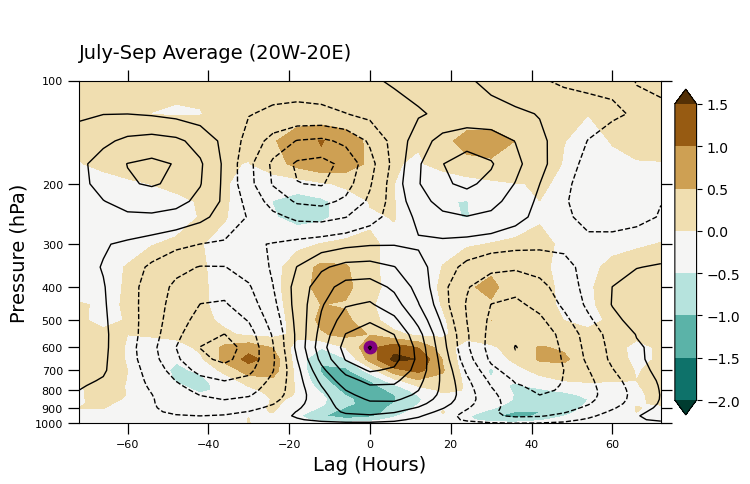

In [16]:
kwargs = dict(
              extend='both',
              add_colorbar=False,  # don't add individual colorbars for each plot call
              add_labels=False,  # turn off xarray's automatic Lat, lon labels
)

# Generate figure (set its size (width, height) in inches) and axes
plt.figure(figsize=(8,5))
ax = plt.axes()

# Set y-axis to have log-scale
plt.yscale('log')

# Specify which contours should be drawn
levs = np.arange(-2.,2.,.5)
print(levs)

# Plot filled colors
cmap1 = 'BrBG_r'

p = Tflux.plot.contourf(ax=ax, levels=levs, 
                    y='level', yincrease=False,
                    x='Lag', cmap=cmap1, **kwargs)
# kwargs for colorbars
kwargs = dict(orientation='vertical',
                    shrink=0.95, aspect=15, extend='auto', pad=0.02)
cbar = plt.colorbar(p,ax=ax, **kwargs)



# Plot lines
clevs = np.arange(-5.5, 6.6, 1.)
lines = V.plot.contour(ax=ax, levels=clevs, colors='black',
                       linewidths=1., y='level', yincrease=False,
                       x='Lag',
                       add_labels=False)

# Label contour levels 
#ax.clabel(lines, fmt='%d', levels=clevs)

for line, lvl in zip(lines.collections, lines.levels):
    if lvl < 0:
        line.set_linestyle('--')
        line.set_linewidth(1)
    elif lvl == 0:
        line.set_linestyle(':')
        line.set_linewidth(0)
    else:
        line.set_linestyle('-')
        line.set_linewidth(1)


# Use geocat.viz.util convenience function to set axes tick values
# Set y-lim inorder for y-axis to have descending values
gv.set_axes_limits_and_ticks(
    ax,
    ylim=ax.get_ylim()[::-1],
    yticks=V["level"])


# Change formatter or else tick values will be in exponential form
ax.yaxis.set_major_formatter(ScalarFormatter())

# Use geocat.viz.util convenience function to add major tick lines with no
# minor ticks on left hand side y axis and some minor ticks on the x axis
gv.add_major_minor_ticks(ax=ax,
                         x_minor_per_major=1,
                         y_minor_per_major=1,
                         labelsize=8)

# Use geocat.viz.util convenience function to add titles and the pressure label
gv.set_titles_and_labels(ax,
                         maintitle=" ",
                         maintitlefontsize=18,
                         lefttitle='July-Sep Average (20W-20E)',
                         lefttitlefontsize=14,
                         righttitle=" ",
                         righttitlefontsize=14,
                         ylabel='Pressure (hPa)',
                         xlabel='Lag (Hours)',
                         labelfontsize=14)

# Create second y-axis to show geo-potential height.
#axRHS = gv.add_height_from_pressure_axis(ax, heights=np.arange(0,8,1))

ax.invert_yaxis()  # Reverse the time order to do oldest first

# Find at most 11 ticks on the y-axis at 'nice' locations
max_yticks = 11
yloc = plt.MaxNLocator(max_yticks)
ax.yaxis.set_major_locator(yloc)

ax.scatter(0,600,s=80, facecolor='purple')

# Force the plot to be square by setting the aspect ratio to 1
plt.tight_layout()
plt.show()

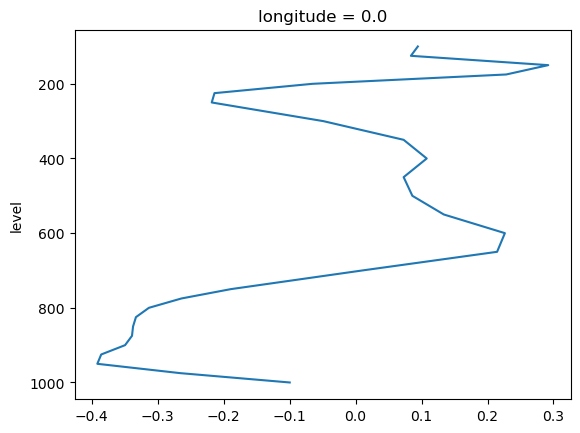

In [14]:
Tflux.mean(dim='Lag').plot(y='level', yincrease=False)